# Analisis Jangkauan Pos Pemadam Kebakaran — Surabaya Timur
Team 4 · Computer Graphics 2026/2027

Alur: validasi data → proyeksi EPSG:32749 → buffer pos → spatial join dengan kecamatan → profil 24 jam → waktu tempuh rute & isochrone 5 menit TomTom (jam lengang vs jam puncak hasil pengukuran).

**Data yang harus ada di `data/`:**
- `kebakaran_2022.csv`: data kebakaran Open Data Surabaya (sudah ada)
- `pos_damkar.csv`: kolom `nama, jenis (rayon/pembantu), lon, lat` (koordinat **wajib diisi** & diverifikasi)
- `idn_admin_boundaries.gdb.zip` (atau hasil unzip `.gdb`) dari HDX: hanya dibutuhkan sekali, notebook menyimpan 11 kecamatan ke `kecamatan_surabaya.geojson`

API key TomTom (gratis, developer.tomtom.com): simpan di file `.tomtom_key`, set env `TOMTOM_API_KEY`, atau masukkan saat diminta oleh cell waktu tempuh.

In [18]:
%pip install -q geopandas matplotlib requests


[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [19]:
import os, json, re
from datetime import date, datetime
from pathlib import Path
from zoneinfo import ZoneInfo

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import requests

DATA = Path("data")
OUT = Path("output"); OUT.mkdir(exist_ok=True)
KECAMATAN_PATH = DATA / "kecamatan_surabaya.geojson"   # hasil potongan, dibuat otomatis dari file HDX
HDX_GDB = [DATA / "idn_admin_boundaries.gdb", DATA / "idn_admin_boundaries.gdb.zip"]   # download dari HDX cod-ab-idn

STUDI = ["Gubeng", "Gunung Anyar", "Mulyorejo", "Rungkut", "Sukolilo", "Tambaksari",
         "Tenggilis Mejoyo", "Bulak", "Kenjeran", "Genteng", "Wonocolo"]
CRS_UTM = "EPSG:32749"
RADIUS_M = {"pembantu": 2500, "rayon": 3500}   # Permen PU 20/PRT/M/2009
TANGGAL_SAMPEL = date(2026, 10, 28)              # Rabu (hari kerja); departAt TomTom harus di masa depan
BATAS_TEMPUH_MENIT = 5                          # porsi perjalanan dari 15 menit waktu tanggap

def kunci(nama):
    # samakan penulisan nama kecamatan: 'Gunung Anyar' == 'Gununganyar'
    return re.sub(r"[^a-z]", "", str(nama).lower())

## 1. Data kejadian kebakaran 2022 per kecamatan

In [20]:
raw = pd.read_csv(DATA / "kebakaran_2022.csv", header=2)
raw = raw[pd.to_numeric(raw["No"], errors="coerce").notna()]   # buang baris (1),(2).. dan baris kosong
raw["Kecamatan"] = raw["Kecamatan"].fillna("").str.strip().str.title()
print("Total kejadian Surabaya 2022:", len(raw))
print("Tanpa kecamatan (cek manual dari alamat):")
display(raw.loc[raw["Kecamatan"] == "", ["No", "Lokasi Kejadian Kebakaran"]])

kejadian = (raw[raw["Kecamatan"].isin(STUDI)]
            .groupby("Kecamatan").size().rename("jumlah_kejadian").reset_index())
kejadian["key"] = kejadian["Kecamatan"].map(kunci)
print("Kejadian di wilayah studi:", kejadian["jumlah_kejadian"].sum())
kejadian.sort_values("jumlah_kejadian", ascending=False)

Total kejadian Surabaya 2022: 625
Tanpa kecamatan (cek manual dari alamat):


,No,Lokasi Kejadian Kebakaran
9,9,Jl. Kepuh Kiriman Dalam Gg. Masjid
17,17,"Jl. Kidemang Singomenggolo No.KM 20, RW.No.6 (..."
58,58,JL. Sidowungu no 59 (CV.Jati Bening)
69,69,PT.Surabaya Mekabox Jl.Raya Bambe No 18
209,209,Jl. Mayjend Sungkono No.8
217,217,Jl. Raya Trosobo No.111
292,292,The Royal Crown Palace Ruko Blok RB - 7 ( Cent...
312,312,Jl. Randegansari No.29


Kejadian di wilayah studi: 257


,Kecamatan,jumlah_kejadian,key
7,Sukolilo,44,sukolilo
2,Gubeng,31,gubeng
8,Tambaksari,30,tambaksari
5,Mulyorejo,27,mulyorejo
4,Kenjeran,23,kenjeran
6,Rungkut,23,rungkut
3,Gunung Anyar,19,gununganyar
1,Genteng,18,genteng
9,Tenggilis Mejoyo,18,tenggilismejoyo
10,Wonocolo,14,wonocolo


## 2. Validasi layer

In [21]:
def validasi(gdf, id_col, nama):
    assert gdf.crs is not None, f"{nama}: CRS kosong"
    assert not gdf.geometry.is_empty.any() and gdf.geometry.notna().all(), f"{nama}: ada geometri kosong"
    if not gdf.geometry.is_valid.all():
        print(f"{nama}: geometri tidak valid diperbaiki dengan make_valid()")
        gdf = gdf.set_geometry(gdf.geometry.make_valid())
    assert gdf[id_col].is_unique, f"{nama}: {id_col} tidak unik"
    print(f"{nama}: {len(gdf)} fitur, CRS {gdf.crs.to_string()}, bounds {gdf.total_bounds.round(4)}")
    return gdf

### Layer 2 — Batas kecamatan (Polygon)

In [22]:
import pyogrio

if KECAMATAN_PATH.exists():
    kec_all = gpd.read_file(KECAMATAN_PATH)
else:
    gdb = next((p for p in HDX_GDB if p.exists()), None)
    assert gdb, f"Taruh file HDX di salah satu: {[str(p) for p in HDX_GDB]}"
    layer = next(n for n, _ in pyogrio.list_layers(gdb) if "adm3" in n.lower() or "admin3" in n.lower())
    # bbox Surabaya supaya tidak memuat seluruh Indonesia
    kec_all = gpd.read_file(gdb, layer=layer, bbox=(112.55, -7.40, 112.90, -7.15))
nama_col = next(c for c in ["adm3_name", "ADM3_EN", "ADM3_ID", "NAME_3", "shapeName", "WADMKC"] if c in kec_all.columns)
kota_col = next((c for c in ["adm2_name", "ADM2_EN", "ADM2_ID", "NAME_2", "WADMKK"] if c in kec_all.columns), None)
# nama seperti Genteng/Sukolilo juga ada di kabupaten lain, jadi filter Kota Surabaya dulu
if kota_col:
    kec_all = kec_all[kec_all[kota_col].str.contains("Surabaya", case=False, na=False)]

kec = kec_all.assign(key=kec_all[nama_col].map(kunci))
kec = kec[kec["key"].isin({kunci(k) for k in STUDI})].dissolve(by="key").reset_index()
hilang = {kunci(k) for k in STUDI} - set(kec["key"])
assert not hilang, f"Kecamatan tidak ditemukan di file batas: {hilang}"
if not KECAMATAN_PATH.exists():
    kec.to_file(KECAMATAN_PATH, driver="GeoJSON")   # simpan 11 kecamatan saja; file HDX boleh dihapus setelah ini

kec = kec.merge(kejadian[["key", "Kecamatan", "jumlah_kejadian"]], on="key", how="left")[["key", "Kecamatan", "jumlah_kejadian", "geometry"]]
kec = validasi(kec.to_crs("EPSG:4326"), "key", "Kecamatan")

Kecamatan: 11 fitur, CRS EPSG:4326, bounds [112.7293  -7.3465 112.8468  -7.1957]


### Layer 1 — Titik pos Damkar (Point)

In [23]:
pos_df = pd.read_csv(DATA / "pos_damkar.csv")
pos_df["jenis"] = pos_df["jenis"].str.strip().str.lower()
assert pos_df[["lon", "lat"]].notna().all().all(), "Isi dulu lon/lat semua pos di data/pos_damkar.csv"
assert pos_df["jenis"].isin(RADIUS_M).all(), f"jenis harus salah satu dari {list(RADIUS_M)}"
# urutan longitude lalu latitude; cek kasar masih di sekitar Surabaya agar tidak tertukar
assert pos_df["lon"].between(112.5, 113.0).all() and pos_df["lat"].between(-7.5, -7.1).all(), "Koordinat di luar Surabaya / lon-lat tertukar"
assert len(pos_df) >= 4, "Analisis memakai minimal 4 pos"

pos = gpd.GeoDataFrame(pos_df, geometry=gpd.points_from_xy(pos_df["lon"], pos_df["lat"]), crs="EPSG:4326")
pos = validasi(pos, "nama", "Pos Damkar")
pos

Pos Damkar: 7 fitur, CRS EPSG:4326, bounds [112.7138  -7.3367 112.8017  -7.2318]


,nama,jenis,lon,lat,geometry
0,Rayon/UPTD III (SIER),rayon,112.754070,-7.336707,POINT (112.75407 -7.33671)
1,Pos Kali Rungkut,pembantu,112.769998,-7.322148,POINT (112.77 -7.32215)
2,Pos Sukolilo (Keputih),pembantu,112.801729,-7.295276,POINT (112.80173 -7.29528)
3,Pos Bulak,pembantu,112.785459,-7.231831,POINT (112.78546 -7.23183)
4,UPTD II Tambak Rejo,rayon,112.759729,-7.243086,POINT (112.75973 -7.24309)
5,Mako Pasar Turi,rayon,112.736357,-7.244985,POINT (112.73636 -7.24498)
6,Pos Jambangan,pembantu,112.713816,-7.322137,POINT (112.71382 -7.32214)


## 3. Proyeksi ke UTM 49S (meter)

In [24]:
kec_m = kec.to_crs(CRS_UTM)
pos_m = pos.to_crs(CRS_UTM)
kec_m["luas_km2"] = (kec_m.area / 1e6).round(2)
kec_m[["Kecamatan", "jumlah_kejadian", "luas_km2"]]

,Kecamatan,jumlah_kejadian,luas_km2
0,Bulak,10,6.09
1,Genteng,18,4.12
2,Gubeng,31,7.90
3,Gunung Anyar,19,10.27
4,Kenjeran,23,8.64
5,Mulyorejo,27,17.73
6,Rungkut,23,22.93
7,Sukolilo,44,30.24
8,Tambaksari,30,8.88
9,Tenggilis Mejoyo,18,5.78


## 4. Operasi 1 — Buffer zona jangkauan

In [25]:
pos_m["radius_m"] = pos_m["jenis"].map(RADIUS_M)
buffer_m = pos_m.copy()
buffer_m["geometry"] = pos_m.buffer(pos_m["radius_m"])
buffer_m[["nama", "jenis", "radius_m"]]

,nama,jenis,radius_m
0,Rayon/UPTD III (SIER),rayon,3500
1,Pos Kali Rungkut,pembantu,2500
2,Pos Sukolilo (Keputih),pembantu,2500
3,Pos Bulak,pembantu,2500
4,UPTD II Tambak Rejo,rayon,3500
5,Mako Pasar Turi,rayon,3500
6,Pos Jambangan,pembantu,2500


## 5. Operasi 2 — Spatial join & status jangkauan

In [26]:
def status_jangkauan(kec_m, buffer_m):
    hit = gpd.sjoin(kec_m[["key", "geometry"]], buffer_m[["nama", "geometry"]], predicate="intersects")
    # satu kecamatan bisa cocok dengan beberapa buffer -> dihitung per kecamatan unik
    pos_per_kec = hit.groupby("key")["nama"].apply(lambda s: ", ".join(sorted(s)))
    centroid_masuk = kec_m.centroid.within(buffer_m.union_all())
    status = pd.Series("belum terjangkau", index=kec_m.index)
    status[kec_m["key"].isin(pos_per_kec.index)] = "terjangkau sebagian"
    status[centroid_masuk] = "terjangkau"
    return status, kec_m["key"].map(pos_per_kec).fillna("-")

kec_m["status"], kec_m["pos_beririsan"] = status_jangkauan(kec_m, buffer_m)
tabel_jarak = kec_m[["Kecamatan", "jumlah_kejadian", "status", "pos_beririsan"]].sort_values("jumlah_kejadian", ascending=False)
tabel_jarak

,Kecamatan,jumlah_kejadian,status,pos_beririsan
7,Sukolilo,44,terjangkau,"Pos Kali Rungkut, Pos Sukolilo (Keputih), Rayo..."
2,Gubeng,31,terjangkau sebagian,"Mako Pasar Turi, Pos Kali Rungkut, Rayon/UPTD ..."
8,Tambaksari,30,terjangkau,"Mako Pasar Turi, Pos Bulak, UPTD II Tambak Rejo"
5,Mulyorejo,27,terjangkau sebagian,"Pos Bulak, Pos Sukolilo (Keputih), UPTD II Tam..."
4,Kenjeran,23,terjangkau,"Mako Pasar Turi, Pos Bulak, UPTD II Tambak Rejo"
6,Rungkut,23,terjangkau sebagian,"Pos Kali Rungkut, Pos Sukolilo (Keputih), Rayo..."
3,Gunung Anyar,19,terjangkau sebagian,"Pos Kali Rungkut, Rayon/UPTD III (SIER)"
1,Genteng,18,terjangkau,"Mako Pasar Turi, UPTD II Tambak Rejo"
9,Tenggilis Mejoyo,18,terjangkau,"Pos Kali Rungkut, Rayon/UPTD III (SIER)"
10,Wonocolo,14,terjangkau,"Pos Jambangan, Pos Kali Rungkut, Rayon/UPTD II..."


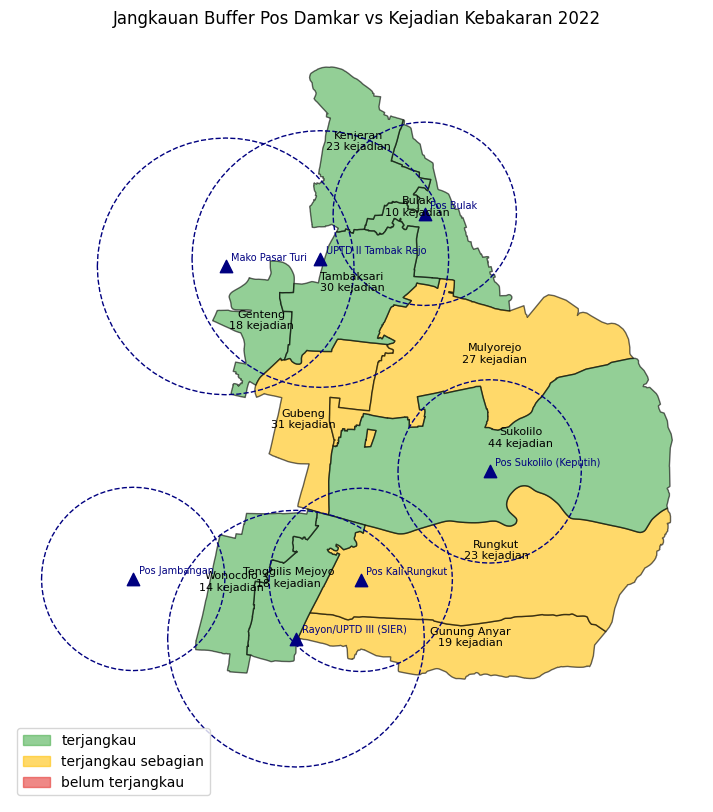

In [27]:
warna = {"terjangkau": "#4caf50", "terjangkau sebagian": "#ffc107", "belum terjangkau": "#e53935"}
fig, ax = plt.subplots(figsize=(10, 10))
kec_m.plot(ax=ax, color=kec_m["status"].map(warna), edgecolor="black", alpha=0.6)
buffer_m.boundary.plot(ax=ax, color="navy", linestyle="--", linewidth=1)
pos_m.plot(ax=ax, color="navy", marker="^", markersize=80, zorder=3)
for _, r in kec_m.iterrows():
    c = r.geometry.representative_point()
    ax.annotate(f"{r['Kecamatan']}\n{r['jumlah_kejadian']} kejadian", (c.x, c.y), ha="center", fontsize=8)
for _, r in pos_m.iterrows():
    ax.annotate(r["nama"], (r.geometry.x, r.geometry.y), xytext=(4, 4), textcoords="offset points", fontsize=7, color="navy")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c, alpha=0.6) for c in warna.values()], labels=list(warna), loc="lower left")
ax.set_title("Jangkauan Buffer Pos Damkar vs Kejadian Kebakaran 2022")
ax.set_axis_off()
fig.savefig(OUT / "peta_jangkauan_buffer.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Fitur tambahan — Waktu tempuh & jangkauan nyata berdasarkan jam (TomTom)
Semua perhitungan memakai jaringan jalan dan lalu lintas historis TomTom pada `TANGGAL_SAMPEL` (hari kerja), bukan garis lurus.
1. **Profil 24 jam**: jam lengang dan jam puncak dipilih dari data, bukan ditebak.
2. **Waktu tempuh rute**: dari setiap pos ke centroid setiap kecamatan, diambil pos tercepat.
3. **Isochrone 5 menit**: area yang benar-benar bisa dicapai lewat jalan dalam 5 menit, dibandingkan dengan buffer lingkaran.

Semua respons disimpan di `output/tomtom_cache.json`; run ulang hanya mengirim request yang belum ada di cache.

In [28]:
import time
from getpass import getpass
from shapely.geometry import Polygon

WIB = ZoneInfo("Asia/Jakarta")
CACHE = OUT / "tomtom_cache.json"
cache = json.loads(CACHE.read_text()) if CACHE.exists() else {}
sesi = requests.Session()   # pakai ulang koneksi TLS, jauh lebih cepat dari requests.get per request
_key = None

def tomtom(endpoint, lokasi, **params):
    global _key
    ck = f"{endpoint}/{lokasi}?{json.dumps(params, sort_keys=True)}"
    if ck not in cache:
        if _key is None:
            KEY_FILE = Path(".tomtom_key")   # file lokal, jangan ikut dikumpulkan
            _key = os.environ.get("TOMTOM_API_KEY") or (KEY_FILE.read_text().strip() if KEY_FILE.exists() else getpass("TomTom API key: "))
        r = sesi.get(f"https://api.tomtom.com/routing/1/{endpoint}/{lokasi}/json", timeout=30,
                     params={"key": _key, "travelMode": "car", "traffic": "true", **params})
        assert r.ok, f"TomTom error {r.status_code}: {r.text[:200]}"
        cache[ck] = r.json()
        time.sleep(0.2)   # batas request per detik akun gratis
    return cache[ck]

def simpan_cache():
    CACHE.write_text(json.dumps(cache))

def berangkat(jam):
    return datetime.combine(TANGGAL_SAMPEL, datetime.min.time(), tzinfo=WIB).replace(hour=jam).isoformat()

def rute(asal, tujuan, jam):
    s = tomtom("calculateRoute", f"{asal.y},{asal.x}:{tujuan.y},{tujuan.x}",
               routeType="fastest", departAt=berangkat(jam))["routes"][0]["summary"]
    return s["travelTimeInSeconds"] / 60, s["lengthInMeters"] / 1000

tujuan = kec_m.centroid.to_crs("EPSG:4326")

### 6.1 Profil waktu tempuh 24 jam (memilih jam skenario)

Skenario terpilih: {'lengang_0200': 2, 'puncak_pagi_0800': 8, 'puncak_sore_1700': 17}


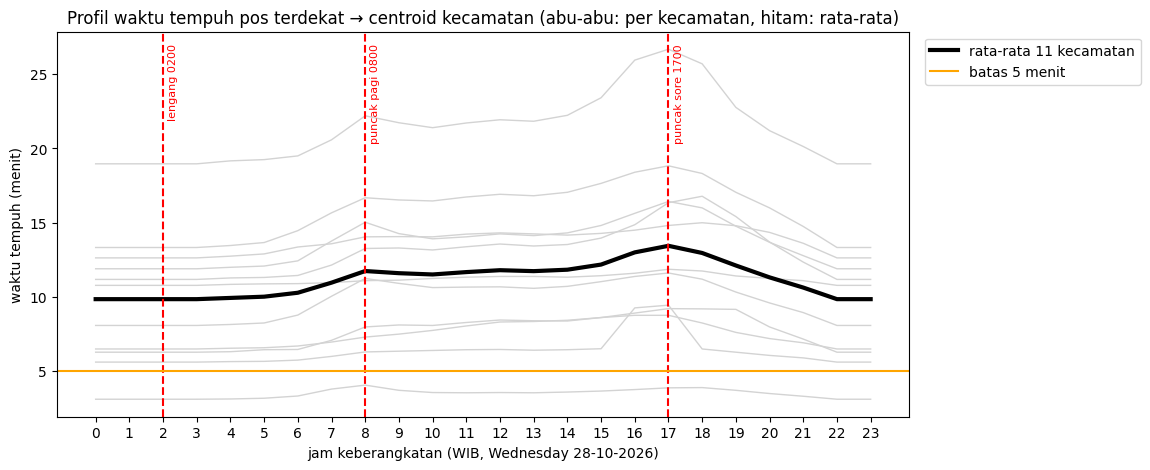

,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
Kecamatan,,,,,,,,,,,,,,,,,,,,,
Bulak,10.8,10.8,10.8,10.8,10.8,10.9,10.9,11.0,11.1,11.1,...,11.3,11.4,11.6,11.9,11.8,11.4,11.2,11.1,10.8,10.8
Genteng,6.5,6.5,6.5,6.5,6.6,6.6,6.7,7.0,7.3,7.5,...,8.4,8.6,8.8,8.8,8.2,7.6,7.2,6.9,6.5,6.5
Gubeng,13.3,13.3,13.3,13.3,13.5,13.7,14.5,15.7,16.7,16.5,...,17.0,17.6,18.4,18.8,18.3,17.0,16.0,14.8,13.3,13.3
Gunung Anyar,11.2,11.2,11.2,11.2,11.3,11.3,11.4,12.2,13.3,13.3,...,13.5,14.0,14.9,16.4,16.8,15.4,13.7,12.4,11.2,11.2
Kenjeran,12.6,12.6,12.6,12.6,12.8,12.9,13.4,13.6,14.0,14.1,...,14.2,14.3,14.5,14.8,15.0,14.8,14.4,13.6,12.6,12.6
Mulyorejo,11.9,11.9,11.9,11.9,12.0,12.1,12.4,13.8,15.0,14.3,...,14.3,14.8,15.6,16.4,16.0,14.8,13.7,12.8,11.9,11.9
Rungkut,19.0,19.0,19.0,19.0,19.2,19.2,19.5,20.6,22.2,21.7,...,22.2,23.4,26.0,26.7,25.7,22.8,21.2,20.1,19.0,19.0
Sukolilo,3.1,3.1,3.1,3.1,3.1,3.2,3.3,3.8,4.1,3.7,...,3.6,3.7,3.8,3.9,3.9,3.7,3.5,3.3,3.1,3.1
Tambaksari,6.3,6.3,6.3,6.3,6.3,6.4,6.5,7.1,8.0,8.1,...,8.4,8.6,8.9,9.2,9.2,9.2,8.0,7.2,6.3,6.3


In [29]:
# sampel: pos terdekat (garis lurus) ke centroid tiap kecamatan, 11 rute x 24 jam
terdekat_lurus = [pos_m.distance(c).idxmin() for c in kec_m.centroid]
profil = pd.DataFrame({jam: [rute(pos.geometry[i], t, jam)[0] for i, t in zip(terdekat_lurus, tujuan)] for jam in range(24)},
                      index=kec_m["Kecamatan"])
simpan_cache()

rata = profil.mean()
# 00.00-03.00 biasanya sama lengangnya; kalau seri pilih 02.00 sesuai laporan
JAM_LENGANG = min(range(6), key=lambda j: (round(rata[j], 1), abs(j - 2)))
JAM_PAGI = int(rata.loc[5:11].idxmax())
JAM_SORE = int(rata.loc[12:20].idxmax())
SKENARIO = {f"lengang_{JAM_LENGANG:02d}00": JAM_LENGANG,
            f"puncak_pagi_{JAM_PAGI:02d}00": JAM_PAGI,
            f"puncak_sore_{JAM_SORE:02d}00": JAM_SORE}
print("Skenario terpilih:", SKENARIO)

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(profil.columns, profil.T.values, color="lightgray", linewidth=1)   # tanpa label: tidak masuk legend
ax.plot(rata.index, rata.values, color="black", linewidth=3, label="rata-rata 11 kecamatan")
for nama, jam in SKENARIO.items():
    ax.axvline(jam, color="red", linestyle="--")
    ax.text(jam + 0.15, 0.97, nama.replace("_", " "), transform=ax.get_xaxis_transform(), rotation=90, va="top", fontsize=8, color="red")
ax.axhline(BATAS_TEMPUH_MENIT, color="orange", label=f"batas {BATAS_TEMPUH_MENIT} menit")
ax.set_xticks(range(24))
ax.set_xlabel(f"jam keberangkatan (WIB, {TANGGAL_SAMPEL:%A %d-%m-%Y})")
ax.set_ylabel("waktu tempuh (menit)")
ax.set_title("Profil waktu tempuh pos terdekat → centroid kecamatan (abu-abu: per kecamatan, hitam: rata-rata)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
fig.savefig(OUT / "profil_waktu_tempuh_24jam.png", dpi=200, bbox_inches="tight")
plt.show()
profil.round(1)

### 6.2 Waktu tempuh rute pos tercepat per kecamatan

In [30]:
rute_df = pd.DataFrame([{"skenario": nama, "pos": pn, "key": k, "menit": m, "km": km}
                        for nama, jam in SKENARIO.items()
                        for pn, pg in zip(pos["nama"], pos.geometry)
                        for k, t in zip(kec_m["key"], tujuan)
                        for m, km in [rute(pg, t, jam)]])
simpan_cache()

tempuh = kec_m[["key", "Kecamatan", "jumlah_kejadian", "status"]].copy()
for nama in SKENARIO:
    t = rute_df[rute_df["skenario"] == nama].reset_index(drop=True)
    terdekat = t.loc[t.groupby("key")["menit"].idxmin()].set_index("key")   # pos tercepat per kecamatan
    tempuh[f"menit_{nama}"] = tempuh["key"].map(terdekat["menit"]).round(1)
    tempuh[f"pos_{nama}"] = tempuh["key"].map(terdekat["pos"])
    tempuh[f"ok_{nama}"] = tempuh[f"menit_{nama}"] <= BATAS_TEMPUH_MENIT

lengang, *puncak = SKENARIO
tempuh["lolos_lengang_gagal_puncak"] = tempuh[f"ok_{lengang}"] & ~tempuh[[f"ok_{p}" for p in puncak]].all(axis=1)
tempuh.drop(columns="key").sort_values("jumlah_kejadian", ascending=False)

,Kecamatan,jumlah_kejadian,status,menit_lengang_0200,pos_lengang_0200,ok_lengang_0200,menit_puncak_pagi_0800,pos_puncak_pagi_0800,ok_puncak_pagi_0800,menit_puncak_sore_1700,pos_puncak_sore_1700,ok_puncak_sore_1700,lolos_lengang_gagal_puncak
7,Sukolilo,44,terjangkau,3.1,Pos Sukolilo (Keputih),True,4.1,Pos Sukolilo (Keputih),True,3.9,Pos Sukolilo (Keputih),True,False
2,Gubeng,31,terjangkau sebagian,11.8,Pos Kali Rungkut,False,16.7,UPTD II Tambak Rejo,False,18.8,UPTD II Tambak Rejo,False,False
8,Tambaksari,30,terjangkau,6.3,UPTD II Tambak Rejo,False,8.0,UPTD II Tambak Rejo,False,9.2,UPTD II Tambak Rejo,False,False
5,Mulyorejo,27,terjangkau sebagian,11.9,Pos Sukolilo (Keputih),False,15.0,Pos Sukolilo (Keputih),False,16.4,Pos Sukolilo (Keputih),False,False
4,Kenjeran,23,terjangkau,11.9,UPTD II Tambak Rejo,False,13.7,UPTD II Tambak Rejo,False,14.8,Pos Bulak,False,False
6,Rungkut,23,terjangkau sebagian,12.1,Pos Kali Rungkut,False,13.6,Pos Kali Rungkut,False,14.9,Pos Kali Rungkut,False,False
3,Gunung Anyar,19,terjangkau sebagian,11.2,Pos Kali Rungkut,False,13.3,Pos Kali Rungkut,False,16.4,Pos Kali Rungkut,False,False
1,Genteng,18,terjangkau,6.5,Mako Pasar Turi,False,7.3,Mako Pasar Turi,False,8.8,Mako Pasar Turi,False,False
9,Tenggilis Mejoyo,18,terjangkau,5.6,Rayon/UPTD III (SIER),False,6.3,Rayon/UPTD III (SIER),False,9.4,Rayon/UPTD III (SIER),False,False
10,Wonocolo,14,terjangkau,8.1,Rayon/UPTD III (SIER),False,11.2,Rayon/UPTD III (SIER),False,11.6,Rayon/UPTD III (SIER),False,False


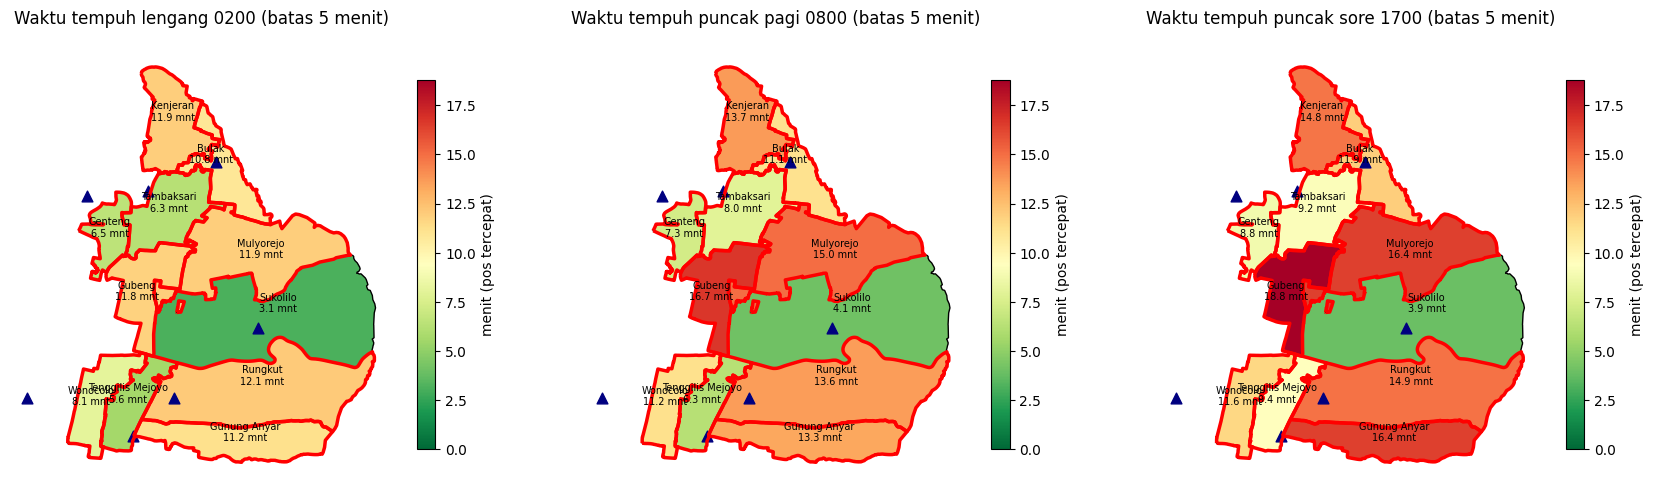

Kecamatan memenuhi batas saat lengang tapi tidak saat jam puncak:
-


In [31]:
peta = kec_m.merge(tempuh.drop(columns=["Kecamatan", "jumlah_kejadian", "status"]), on="key")
vmax = peta[[f"menit_{s}" for s in SKENARIO]].max().max()
fig, axes = plt.subplots(1, len(SKENARIO), figsize=(7 * len(SKENARIO), 8))
for ax, nama in zip(axes, SKENARIO):
    peta.plot(ax=ax, column=f"menit_{nama}", cmap="RdYlGn_r", vmin=0, vmax=vmax, edgecolor="black", legend=True,
              legend_kwds={"label": "menit (pos tercepat)", "shrink": 0.6})
    peta[~peta[f"ok_{nama}"]].boundary.plot(ax=ax, color="red", linewidth=2.5)   # garis merah = > 5 menit
    pos_m.plot(ax=ax, color="navy", marker="^", markersize=60)
    for _, r in peta.iterrows():
        c = r.geometry.representative_point()
        ax.annotate(f"{r['Kecamatan']}\n{r[f'menit_{nama}']} mnt", (c.x, c.y), ha="center", fontsize=7)
    ax.set_title(f"Waktu tempuh {nama.replace('_', ' ')} (batas {BATAS_TEMPUH_MENIT} menit)")
    ax.set_axis_off()
fig.savefig(OUT / "peta_waktu_tempuh.png", dpi=200, bbox_inches="tight")
plt.show()

print("Kecamatan memenuhi batas saat lengang tapi tidak saat jam puncak:")
print(tempuh.loc[tempuh["lolos_lengang_gagal_puncak"], "Kecamatan"].tolist() or "-")

Peta rute: jalur jalan dari pos tercepat ke centroid tiap kecamatan (geometri dari respons TomTom yang sudah di-cache).

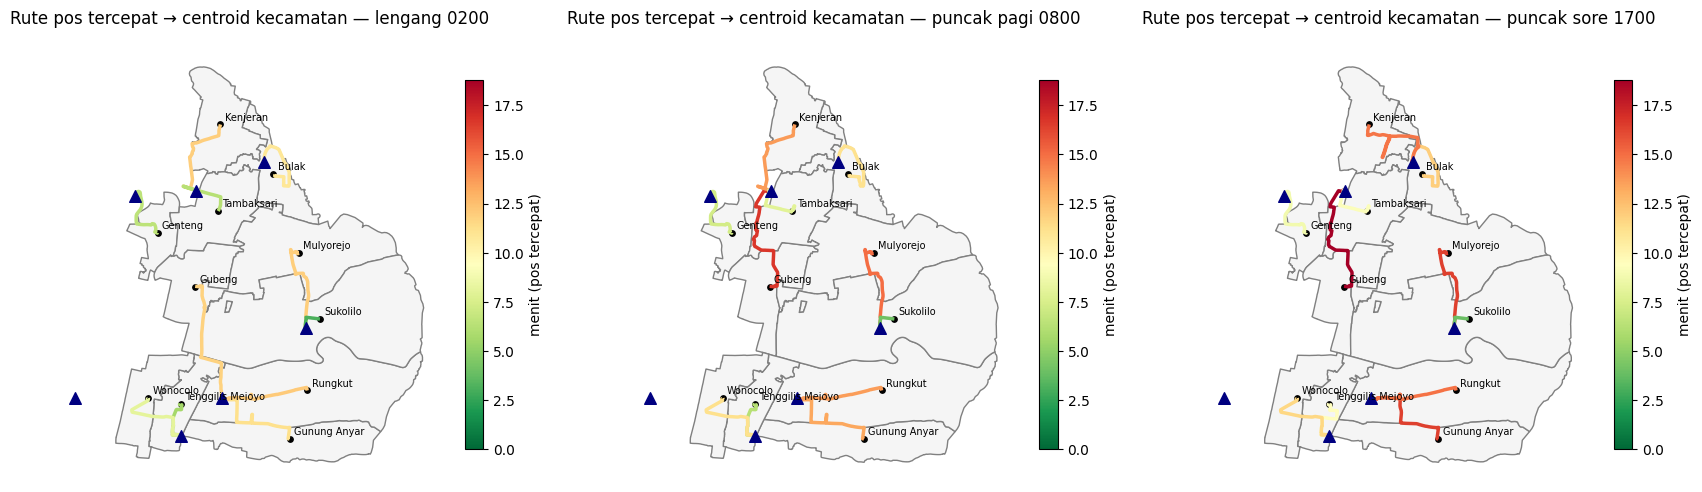

In [32]:
from shapely.geometry import LineString

def garis_rute(asal, tujuan, jam):
    r = tomtom("calculateRoute", f"{asal.y},{asal.x}:{tujuan.y},{tujuan.x}", routeType="fastest", departAt=berangkat(jam))["routes"][0]
    return LineString([(t["longitude"], t["latitude"]) for leg in r["legs"] for t in leg["points"]])

geom_pos = dict(zip(pos["nama"], pos.geometry))
geom_tujuan = dict(zip(kec_m["key"], tujuan))
fig, axes = plt.subplots(1, len(SKENARIO), figsize=(7 * len(SKENARIO), 8))
for ax, (nama, jam) in zip(axes, SKENARIO.items()):
    jalur = gpd.GeoDataFrame({"menit": tempuh[f"menit_{nama}"].values},
                             geometry=[garis_rute(geom_pos[p], geom_tujuan[k], jam) for k, p in zip(tempuh["key"], tempuh[f"pos_{nama}"])],
                             crs="EPSG:4326").to_crs(CRS_UTM)
    kec_m.plot(ax=ax, color="whitesmoke", edgecolor="gray")
    jalur.plot(ax=ax, column="menit", cmap="RdYlGn_r", vmin=0, vmax=vmax, linewidth=2.5, legend=True,
               legend_kwds={"label": "menit (pos tercepat)", "shrink": 0.6})
    kec_m.centroid.plot(ax=ax, color="black", markersize=15)
    pos_m.plot(ax=ax, color="navy", marker="^", markersize=70, zorder=3)
    for _, r in kec_m.iterrows():
        ax.annotate(r["Kecamatan"], (r.geometry.centroid.x, r.geometry.centroid.y), xytext=(3, 3), textcoords="offset points", fontsize=7)
    ax.set_title(f"Rute pos tercepat → centroid kecamatan — {nama.replace('_', ' ')}")
    ax.set_axis_off()
simpan_cache()
fig.savefig(OUT / "peta_rute.png", dpi=200, bbox_inches="tight")
plt.show()

### 6.3 Isochrone 5 menit: jangkauan nyata lewat jalan
`calculateReachableRange` TomTom mengembalikan poligon area yang bisa dicapai dari tiap pos dalam 5 menit dengan kondisi lalu lintas jam tersebut.
Berbeda dengan buffer (lingkaran garis lurus) dan rute ke centroid (satu titik), isochrone menilai seluruh wilayah kecamatan.

In [33]:
def isochrone(p, jam):
    b = tomtom("calculateReachableRange", f"{p.y},{p.x}", timeBudgetInSec=BATAS_TEMPUH_MENIT * 60,
               departAt=berangkat(jam))["reachableRange"]["boundary"]
    return Polygon([(t["longitude"], t["latitude"]) for t in b])

iso = gpd.GeoDataFrame([{"skenario": nama, "pos": pn, "geometry": isochrone(pg, jam)}
                        for nama, jam in SKENARIO.items() for pn, pg in zip(pos["nama"], pos.geometry)],
                       crs="EPSG:4326").to_crs(CRS_UTM)
simpan_cache()
iso["geometry"] = iso.make_valid()

for nama in SKENARIO:
    zona = iso[iso["skenario"] == nama].union_all()
    tempuh[f"pct_5mnt_{nama}"] = (kec_m.intersection(zona).area / kec_m.area * 100).round(1)

ringkasan = tempuh.drop(columns="key").sort_values("jumlah_kejadian", ascending=False)
ringkasan.to_csv(OUT / "ringkasan_per_kecamatan.csv", index=False)

luas = iso.assign(luas_km2=iso.area / 1e6).pivot(index="pos", columns="skenario", values="luas_km2")[list(SKENARIO)]
luas.insert(0, "buffer_km2", buffer_m.set_index("nama").area / 1e6)
print("Luas jangkauan per pos: buffer lingkaran vs isochrone 5 menit (km2)")
display(luas.round(2))
ringkasan[["Kecamatan", "jumlah_kejadian", "status"] + [f"pct_5mnt_{n}" for n in SKENARIO]]

Luas jangkauan per pos: buffer lingkaran vs isochrone 5 menit (km2)


skenario,buffer_km2,lengang_0200,puncak_pagi_0800,puncak_sore_1700
pos,,,,
Mako Pasar Turi,38.42,6.39,4.33,3.29
Pos Bulak,19.60,1.33,1.14,1.01
Pos Jambangan,19.60,4.01,2.59,1.68
Pos Kali Rungkut,19.60,6.77,3.65,3.03
Pos Sukolilo (Keputih),19.60,3.49,2.15,2.06
Rayon/UPTD III (SIER),38.42,5.43,3.61,2.55
UPTD II Tambak Rejo,38.42,4.08,1.24,1.05


,Kecamatan,jumlah_kejadian,status,pct_5mnt_lengang_0200,pct_5mnt_puncak_pagi_0800,pct_5mnt_puncak_sore_1700
7,Sukolilo,44,terjangkau,11.2,7.0,6.8
2,Gubeng,31,terjangkau sebagian,1.0,0.0,0.0
8,Tambaksari,30,terjangkau,13.9,3.9,2.2
5,Mulyorejo,27,terjangkau sebagian,1.0,0.2,0.1
4,Kenjeran,23,terjangkau,2.8,1.6,1.5
6,Rungkut,23,terjangkau sebagian,19.9,13.9,12.1
3,Gunung Anyar,19,terjangkau sebagian,14.1,8.8,6.4
1,Genteng,18,terjangkau,21.0,5.6,0.7
9,Tenggilis Mejoyo,18,terjangkau,51.3,27.0,19.5
10,Wonocolo,14,terjangkau,5.0,1.7,0.0


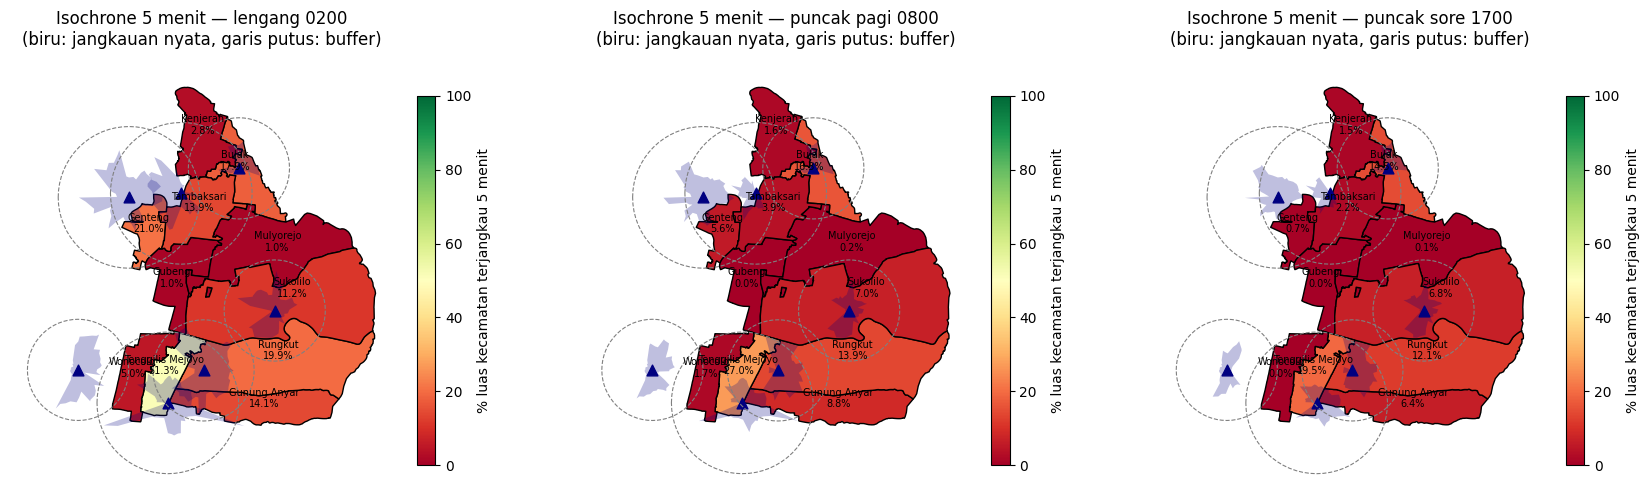

In [34]:
fig, axes = plt.subplots(1, len(SKENARIO), figsize=(7 * len(SKENARIO), 8))
for ax, nama in zip(axes, SKENARIO):
    col = f"pct_5mnt_{nama}"
    kec_m.assign(pct=tempuh[col]).plot(ax=ax, column="pct", cmap="RdYlGn", vmin=0, vmax=100, edgecolor="black", legend=True,
                                       legend_kwds={"label": "% luas kecamatan terjangkau 5 menit", "shrink": 0.6})
    iso[iso["skenario"] == nama].plot(ax=ax, color="navy", alpha=0.25)
    buffer_m.boundary.plot(ax=ax, color="gray", linestyle="--", linewidth=0.8)
    pos_m.plot(ax=ax, color="navy", marker="^", markersize=60)
    for (_, r), pct in zip(kec_m.iterrows(), tempuh[col]):
        c = r.geometry.representative_point()
        ax.annotate(f"{r['Kecamatan']}\n{pct}%", (c.x, c.y), ha="center", fontsize=7)
    ax.set_title(f"Isochrone {BATAS_TEMPUH_MENIT} menit — {nama.replace('_', ' ')}\n(biru: jangkauan nyata, garis putus: buffer)")
    ax.set_axis_off()
fig.savefig(OUT / "peta_isochrone_5mnt.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. Self-check logika status jangkauan

In [35]:
from shapely.geometry import Point, box
_k = gpd.GeoDataFrame({"key": ["a", "b", "c"]}, geometry=[box(0, 0, 10, 10), box(20, 0, 30, 10), box(100, 0, 110, 10)], crs=CRS_UTM)
_b = gpd.GeoDataFrame({"nama": ["p1"]}, geometry=[Point(5, 5).buffer(3)], crs=CRS_UTM)
_b2 = gpd.GeoDataFrame({"nama": ["p1", "p2"]}, geometry=[Point(5, 5).buffer(3), Point(18, 5).buffer(4)], crs=CRS_UTM)
assert list(status_jangkauan(_k, _b)[0]) == ["terjangkau", "belum terjangkau", "belum terjangkau"]
assert list(status_jangkauan(_k, _b2)[0]) == ["terjangkau", "terjangkau sebagian", "belum terjangkau"]
print("OK")

OK
